# C03 — RAID-trained FZ186 baseline on the fixed 54
Fresh kernel; save as `experiments/C03_FZ186_RAID_fixed54.ipynb` and run all.

**Definition:** this is the project's explicit operational FZ186 v1, not a verified reconstruction of the original paper's complete POS block. It appends 68 shallow grammatical features (17 Universal POS categories × 4 summaries) to the existing 118 coordinates. For each tag: share of non-space tokens, mean sentence count, population standard deviation of sentence counts, maximum sentence count. Counts include punctuation/symbol tokens and zero counts in sentences. Sentence segmentation is spaCy's; whitespace-only sentences are omitted. This definition is frozen in a manifest. The existing 118 features retain their established definitions.

Train on original RAID training examples only. Score all 54 completed pipeline outputs without adaptation or new rewriting. Compare full 186 inputs with 182 inputs excluding the same four parenthesis coordinates as Phase One. Frozen FZ118 is retained as a reference. Human validation calibrates thresholds; test humans provide reference contributions and realized FPR. These are discovery diagnostics, not fresh confirmatory outcomes.

Methodological source: [Fröhling & Zubiaga (2021)](https://www.zubiaga.org/publications/files/froehling2021gpt.pdf), whose POS distribution/count features motivate the extension; sentence dispersion/extrema here are our explicit design choices.


In [1]:
from pathlib import Path
import json,hashlib,pickle,re,os
from collections import Counter
from functools import lru_cache
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy,textstat,sklearn
from sklearn.base import clone
from sklearn.metrics import roc_curve,auc
from IPython.display import display
ROOT=Path.cwd() if (Path.cwd()/'results').exists() else Path.cwd().parent
BASE=ROOT/'results/causal/C02d2_fz118_ghostbuster_raid'
PRIOR=ROOT/'results/causal/C02e2_raid_feature_guided'
INPUT=ROOT/'results/causal/C02w_adaptive_camouflage_v1/final_texts_54.csv'
LATEST=ROOT/'results/causal/C02s_relative_likelihood_sensitivity/wps_repair_v1/downstream_v1/hyphen_repair_v1/texts.csv'
FIG=ROOT/'figures';FIG.mkdir(parents=True,exist_ok=True)
normalize=lambda t:str(t).replace('\n',' ').replace('\r',' ')
nlp=spacy.load('en_core_web_sm')
features=pd.read_parquet(BASE/'fz118_paired_features.parquet')
corpus=pd.read_parquet(BASE/'paired_corpus.parquet')
assert features.source_id.is_unique and corpus.source_id.is_unique
text_map=corpus.set_index('source_id').text.to_dict()
data=pd.read_csv(INPUT,keep_default_na=False).sort_values('case_id').reset_index(drop=True)
assert len(data)==54 and data.case_id.is_unique and data.source_id.is_unique
assert data.pipeline_status.eq('complete').all() and data.text.str.strip().ne('').all()
prior27=pd.read_csv(LATEST,keep_default_na=False)
assert len(prior27)==27 and prior27.case_id.is_unique
for r in prior27.itertuples():assert data.set_index('case_id').loc[r.case_id,'text']==r.text
selection=pd.read_csv(ROOT/'results/causal/C02r_discovery_gated_punctuation/selection.csv')
selection=selection.loc[selection.partition.eq('discovery')].sort_values('case_id')
assert data[['case_id','source_id','domain']].reset_index(drop=True).equals(selection[['case_id','source_id','domain']].reset_index(drop=True))
data['batch']=np.where(data.case_id.isin(prior27.case_id),'Original 27','New 27')
SEED=20260909;B=2000
print('Loaded fixed 54; no regeneration or adaptation.')


Loaded fixed 54; no regeneration or adaptation.


In [2]:
import re, pickle
from collections import Counter
import textstat
PUNCTUATION = [('comma', ','), ('period', '.'), ('colon', ':'), ('semicolon', ';'),
    ('question', '?'), ('exclamation', '!'), ('hyphen', '-'), ('quote', '"'),
    ('lparen', '('), ('rparen', ')'), ('lbracket', '['), ('rbracket', ']'), ('newline', '\n')]
google_words=[w.strip().lower() for w in (BASE/'google-10000-english.txt').read_text().splitlines() if w.strip()]
GOOGLE_TOP={n:set(google_words[:n]) for n in [100,1000,10000]}

def safe_div(a, b):
    return float(a) / float(b) if b else 0.0


def clean_word_tokens(span):
    return [
        token.text.lower()
        for token in span
        if token.is_alpha
    ]


def clean_pos_tokens(span):
    return [
        token.pos_
        for token in span
        if token.is_alpha
    ]


def ngram_counter(sequence, n):
    if len(sequence) < n:
        return Counter()
    return Counter(
        tuple(sequence[i:i+n])
        for i in range(len(sequence) - n + 1)
    )


def multiset_overlap(left, right, n):
    a = ngram_counter(left, n)
    b = ngram_counter(right, n)
    denominator = min(sum(a.values()), sum(b.values()))
    if denominator == 0:
        return 0.0
    shared = sum((a & b).values())
    return float(shared / denominator)


def overlap_histogram(sentences, token_fn, n):
    if len(sentences) < 2:
        return np.zeros(10, dtype=np.float64)

    values = [
        multiset_overlap(token_fn(left), token_fn(right), n)
        for left, right in zip(sentences[:-1], sentences[1:])
    ]

    # Include 1.0 in the final bin.
    bins = np.minimum((np.asarray(values) * 10).astype(int), 9)
    counts = np.bincount(bins, minlength=10).astype(np.float64)
    return counts / max(1, len(values))


def conjunction_overlap(sentences, n):
    values = []
    for sentence in sentences:
        words = clean_word_tokens(sentence)
        for i, word in enumerate(words):
            if word == "and":
                values.append(
                    multiset_overlap(words[:i], words[i+1:], n)
                )
    return float(np.mean(values)) if values else 0.0


def punctuation_count(text, symbol_name, symbol):
    if symbol_name == "quote":
        return text.count('"') + text.count("“") + text.count("”")
    return text.count(symbol)


def finite_readability(fn, text):
    try:
        value = float(fn(text))
        return value if np.isfinite(value) else 0.0
    except Exception:
        return 0.0


def extract_fz118(text):
    text = str(text)
    doc = nlp(text)
    sentences = [sent for sent in doc.sents if clean_word_tokens(sent)]
    words = [token.text.lower() for token in doc if token.is_alpha]

    n_characters = len(text)
    n_words = len(words)
    n_sentences = len(sentences)
    n_syllables = int(textstat.syllable_count(text))
    n_difficult = int(textstat.difficult_words(text))
    n_short = sum(len(word) <= 3 for word in words)
    n_long = sum(len(word) >= 7 for word in words)

    values = [
        n_characters,
        n_syllables,
        n_words,
        n_sentences,
        n_difficult,
        n_short,
        n_long,
        safe_div(n_characters, n_words),
        safe_div(n_syllables, n_words),
        safe_div(n_words, n_sentences),
        safe_div(n_difficult, n_words),
        safe_div(n_short, n_words),
        safe_div(n_long, n_words),
        finite_readability(textstat.automated_readability_index, text),
        finite_readability(textstat.coleman_liau_index, text),
        finite_readability(textstat.flesch_kincaid_grade, text),
        finite_readability(textstat.flesch_reading_ease, text),
        finite_readability(textstat.gunning_fog, text),
        finite_readability(textstat.lix, text),
        finite_readability(textstat.mcalpine_eflaw, text),
        finite_readability(textstat.rix, text),
        finite_readability(textstat.smog_index, text),
        safe_div(sum(token.is_stop for token in doc if token.is_alpha), n_words),
        safe_div(len(set(words)), n_words),
        safe_div(sum(word in GOOGLE_TOP[100] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[1000] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[10000] for word in words), n_words),
    ]

    punct_counts = [
        punctuation_count(text, name, symbol)
        for name, symbol in PUNCTUATION
    ]
    values += [safe_div(count, n_characters) for count in punct_counts]
    values += [safe_div(count, n_sentences) for count in punct_counts]

    paragraphs = [p.strip() for p in re.split(r"\n\s*\n", text) if p.strip()]
    paragraph_word_counts = [
        sum(token.is_alpha for token in nlp.make_doc(paragraph))
        for paragraph in paragraphs
    ]
    values += [
        len(paragraphs),
        float(np.mean(paragraph_word_counts)) if paragraph_word_counts else 0.0,
    ]

    for token_fn in [clean_word_tokens, clean_pos_tokens]:
        for n in [1, 2, 3]:
            values += overlap_histogram(sentences, token_fn, n).tolist()

    values += [conjunction_overlap(sentences, n) for n in [1, 2, 3]]

    vector = np.asarray(values, dtype=np.float64)
    assert vector.shape == (118,)
    assert np.isfinite(vector).all()
    return vector
# Exact tree-path contributions, summed across the frozen forest.
FEATURE_NAMES=json.loads((BASE/'fz118_feature_contract.json').read_text())['feature_names']
model_features=json.loads((PRIOR/'fz118_raid_model_features.json').read_text())
with (PRIOR/'fz118_raid_no_parentheses_detector.pkl').open('rb') as f:detector=pickle.load(f)
assert list(detector.classes_)==[0,1]
def contributions(X):
    a=np.asarray(X,dtype=np.float32); output=np.zeros_like(a,dtype=float);bias=0.
    for estimator in detector.estimators_:
        tree=estimator.tree_; value=tree.value[:,0,:].astype(float)
        prob=value[:,1]/value.sum(axis=1);bias+=prob[0]/len(detector.estimators_)
        for i,row in enumerate(a):
            node=0
            while tree.children_left[node]!=tree.children_right[node]:
                feature=tree.feature[node]
                child=tree.children_left[node] if row[feature]<=tree.threshold[node] else tree.children_right[node]
                output[i,feature]+=(prob[child]-prob[node])/len(detector.estimators_)
                node=child
    assert np.allclose(bias+output.sum(axis=1),detector.predict_proba(X)[:,1],atol=1e-8)
    return output


@lru_cache(maxsize=8192)
def vector_for(text): return extract_fz118(normalize(text))
def frame_for(texts):
    return pd.DataFrame([vector_for(t) for t in texts],columns=FEATURE_NAMES)


In [3]:
POS_TAGS=['ADJ','ADP','ADV','AUX','CCONJ','DET','INTJ','NOUN','NUM','PART','PRON','PROPN','PUNCT','SCONJ','SYM','VERB','X']
POS_STATS=['token_share','sentence_mean','sentence_std','sentence_max']
POS_NAMES=[f'pos_{tag}_{stat}' for tag in POS_TAGS for stat in POS_STATS]
F186=FEATURE_NAMES+POS_NAMES
assert len(F186)==186 and len(set(F186))==186
frozen=detector
F114=list(model_features)
assert len(F114)==114 and set(F114)<=set(FEATURE_NAMES)
F182=F114+POS_NAMES
manifest=dict(name='FZ186_project_v1',source='FZ118 plus project-defined POS block; not exact original-paper reproduction',feature_names=F186,pos_tags=POS_TAGS,pos_statistics=POS_STATS,token_denominator='all non-space tokens including punctuation',sentence_policy='spaCy sentences with at least one non-space token; zeros retained',std_ddof=0,excluded_for_182=[f for f in FEATURE_NAMES if f not in F114],spacy=nlp.meta)
nb=ROOT/'experiments/C03_FZ186_RAID_fixed54.ipynb'
paths=[INPUT,LATEST,BASE/'paired_corpus.parquet',BASE/'fz118_paired_features.parquet',BASE/'fz118_feature_contract.json',BASE/'google-10000-english.txt',PRIOR/'fz118_raid_model_features.json',PRIOR/'fz118_raid_no_parentheses_detector.pkl']
contract=dict(manifest=manifest,inputs={str(p.relative_to(ROOT)):hashlib.sha256(p.read_bytes()).hexdigest() for p in paths},code=hashlib.sha256(json.dumps([c['source'] for c in json.loads(nb.read_text())['cells'] if c['cell_type']=='code']).encode()).hexdigest(),sklearn=sklearn.__version__,textstat=getattr(textstat,'__version__',None),seed=SEED)
run=hashlib.sha256(json.dumps(contract,sort_keys=True,default=str).encode()).hexdigest()[:12]
OUT=ROOT/'results/causal/C03_fz186_raid_fixed54'/run;OUT.mkdir(parents=True,exist_ok=True)
(OUT/'contract.json').write_text(json.dumps(contract,indent=2,default=str))
(OUT/'feature_manifest.json').write_text(json.dumps(manifest,indent=2))
def pos_vector(doc):
    tokens=[t for t in doc if not t.is_space]
    assert {t.pos_ for t in tokens}<=set(POS_TAGS),'Unexpected POS label'
    counts=Counter(t.pos_ for t in tokens)
    sentences=[Counter(t.pos_ for t in s if not t.is_space) for s in doc.sents if any(not t.is_space for t in s)]
    out=[]
    for tag in POS_TAGS:
        a=np.array([s[tag] for s in sentences],dtype=float)
        out.extend([counts[tag]/max(len(tokens),1),a.mean() if len(a) else 0.,a.std(ddof=0) if len(a) else 0.,a.max() if len(a) else 0.])
    return out
raid=features.loc[features.dataset.eq('raid')].copy().reset_index(drop=True)
train=raid.loc[raid.split.eq('train')]
assert set(data.source_id).isdisjoint(train.source_id)
assert features.set_index('source_id').loc[data.source_id,'label'].eq(1).all()
def text_hash(t):return hashlib.sha256(normalize(t).strip().encode()).hexdigest()
train_hash={text_hash(text_map[s]) for s in train.source_id}
assert set(data.text.map(text_hash)).isdisjoint(train_hash)
# Cached POS rows resume independently and retain an input hash.
cache=OUT/'pos_cache';cache.mkdir(exist_ok=True)
def pos_frames(texts):
    vectors=[None]*len(texts);missing={}
    for i,t in enumerate(texts):
        t=normalize(t);key=hashlib.sha256(t.encode()).hexdigest();path=cache/f'{key}.json'
        if path.exists():vectors[i]=json.loads(path.read_text())
        else:missing.setdefault(key,dict(text=t,indices=[]))['indices'].append(i)
    keys=list(missing)
    for j,(key,doc) in enumerate(zip(keys,nlp.pipe([missing[k]['text'] for k in keys],batch_size=32))):
        v=pos_vector(doc);path=cache/f'{key}.json';tmp=path.with_suffix('.tmp');tmp.write_text(json.dumps(v));os.replace(tmp,path)
        for i in missing[key]['indices']:vectors[i]=v
        if j%50==0:print('POS extraction',j+1,'/',len(keys),flush=True)
    return pd.DataFrame(vectors,columns=POS_NAMES)
# Verify inherited extraction against stored original features before mixing blocks.
check=raid.groupby(['split','label'],group_keys=False).head(2)
for r in check.itertuples():
    np.testing.assert_allclose(extract_fz118(normalize(text_map[r.source_id])),raid.set_index('source_id').loc[r.source_id,FEATURE_NAMES].to_numpy(float),atol=1e-9,rtol=0,err_msg=f'FZ118 extractor mismatch: {r.source_id}')
XP=pos_frames([text_map[s] for s in raid.source_id])
XR=pd.concat([raid[FEATURE_NAMES].reset_index(drop=True),XP],axis=1)
XF=pd.concat([frame_for(data.text.tolist()).reset_index(drop=True),pos_frames(data.text.tolist())],axis=1)
assert np.isfinite(XR.to_numpy()).all() and np.isfinite(XF.to_numpy()).all()
XF.assign(case_id=data.case_id.to_numpy()).to_csv(OUT/'fixed54_features.csv',index=False)
print('Feature extraction complete:',XR.shape,XF.shape)


POS extraction 1 / 1818
POS extraction 51 / 1818
POS extraction 101 / 1818
POS extraction 151 / 1818
POS extraction 201 / 1818
POS extraction 251 / 1818
POS extraction 301 / 1818
POS extraction 351 / 1818
POS extraction 401 / 1818
POS extraction 451 / 1818
POS extraction 501 / 1818
POS extraction 551 / 1818
POS extraction 601 / 1818
POS extraction 651 / 1818
POS extraction 701 / 1818
POS extraction 751 / 1818
POS extraction 801 / 1818
POS extraction 851 / 1818
POS extraction 901 / 1818
POS extraction 951 / 1818
POS extraction 1001 / 1818
POS extraction 1051 / 1818
POS extraction 1101 / 1818
POS extraction 1151 / 1818
POS extraction 1201 / 1818
POS extraction 1251 / 1818
POS extraction 1301 / 1818
POS extraction 1351 / 1818
POS extraction 1401 / 1818
POS extraction 1451 / 1818
POS extraction 1501 / 1818
POS extraction 1551 / 1818
POS extraction 1601 / 1818
POS extraction 1651 / 1818
POS extraction 1701 / 1818
POS extraction 1751 / 1818
POS extraction 1801 / 1818
POS extraction 1 / 54
PO

In [4]:
# Train only on the unchanged base RAID training split.
train_mask=raid.split.eq('train').to_numpy()
models={'Frozen FZ114':(frozen,F114)}
for name,cols in [('FZ186',F186),('FZ182 matched exclusions',F182)]:
    model=clone(frozen) # same classifier hyperparameters and seed as Phase One
    model.fit(XR.loc[train_mask,cols],raid.loc[train_mask,'label'].astype(int))
    models[name]=(model,cols)
    with (OUT/(name.replace(' ','_')+'.pkl')).open('wb') as f:pickle.dump(model,f)
raid.loc[train_mask,['source_id','domain','label','split']].to_csv(OUT/'training_manifest.csv',index=False)
print('Trained base detectors. No fixed-54 examples were added to training.')


Trained base detectors. No fixed-54 examples were added to training.


## Scores, TPR, and AI-directed contributions
Exact forest-path contributions sum with the forest bias to the AI probability. They are not SHAP values. Rankings report both raw signed contributions and differences from fixed same-genre test-human means. Intervals resample AI cases within genres and condition on those human references. Features are ranked descriptively; small individual contributions do not imply absence of joint signal.


,feature,raw_mean_contribution,human_adjusted_gap,ci_low,ci_high,fraction_AI_directed,block
12,share_long_words,0.004319,0.005583,0.003649,0.007660,0.796296,Inherited FZ118
44,punct_per_sentence_hyphen,0.002733,0.003512,0.002477,0.004708,0.851852,Inherited FZ118
23,share_unique_words,-0.003318,0.003327,-0.000909,0.008155,0.388889,Inherited FZ118
33,punct_relative_hyphen,0.001961,0.003317,0.001983,0.004749,0.777778,Inherited FZ118
7,characters_per_word,0.002407,0.002901,0.002049,0.003660,0.703704,Inherited FZ118
9,words_per_sentence,0.001972,0.002484,0.001805,0.003143,0.870370,Inherited FZ118
8,syllables_per_word,0.002187,0.002323,0.001493,0.003103,0.796296,Inherited FZ118
26,share_google_top10000,-0.000429,0.002303,-0.001134,0.005698,0.611111,Inherited FZ118
90,pos_1gram_overlap_bin_9,0.000867,0.002120,-0.000038,0.004271,0.592593,Inherited FZ118
14,coleman_liau_index,0.001674,0.002024,0.001037,0.003032,0.648148,Inherited FZ118


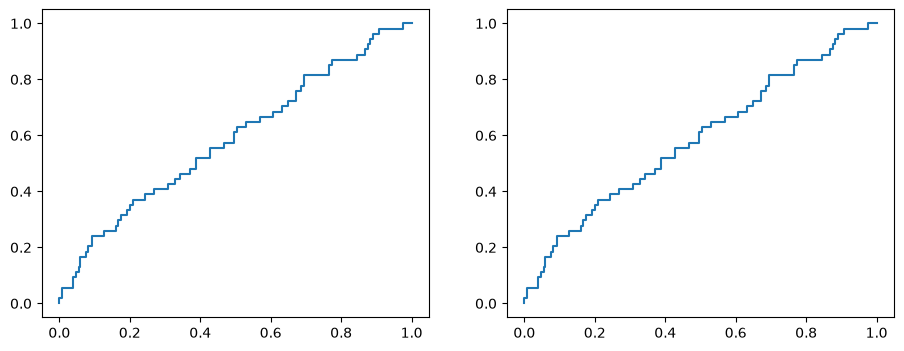

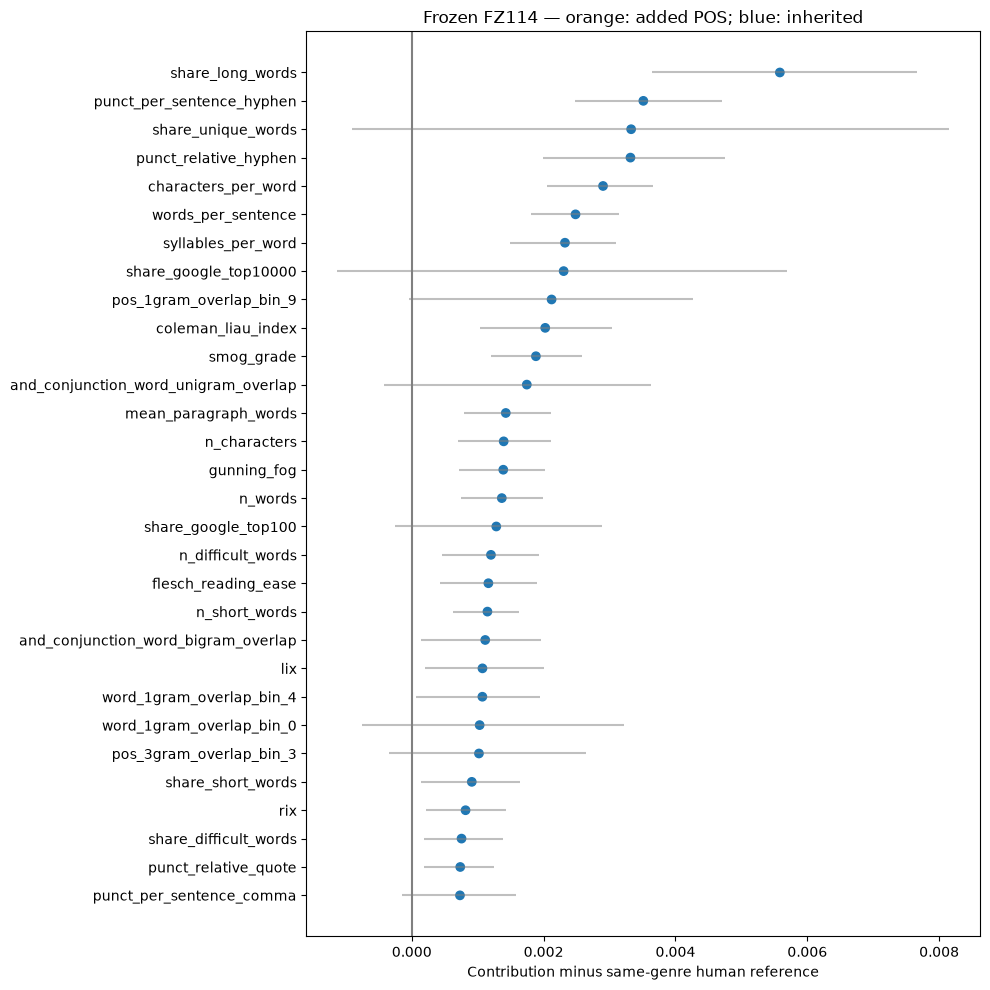

,feature,raw_mean_contribution,human_adjusted_gap,ci_low,ci_high,fraction_AI_directed,block
182,pos_X_token_share,0.006557,0.010668,0.007234,0.013822,0.388889,Added POS
183,pos_X_sentence_mean,0.004290,0.007029,0.004678,0.009139,0.333333,Added POS
184,pos_X_sentence_std,0.003360,0.005304,0.003779,0.006818,0.259259,Added POS
150,pos_NUM_token_share,0.001098,0.004568,0.002473,0.006698,0.722222,Added POS
129,pos_ADV_sentence_max,0.003377,0.004376,0.002838,0.005907,0.759259,Added POS
125,pos_ADP_sentence_max,0.002224,0.004333,0.003219,0.005432,0.833333,Added POS
151,pos_NUM_sentence_mean,0.000685,0.003753,0.001730,0.005771,0.666667,Added POS
120,pos_ADJ_sentence_std,0.000561,0.003549,0.001628,0.005424,0.777778,Added POS
152,pos_NUM_sentence_std,0.000823,0.003494,0.002013,0.005074,0.722222,Added POS
185,pos_X_sentence_max,0.001690,0.003347,0.002019,0.004672,0.203704,Added POS


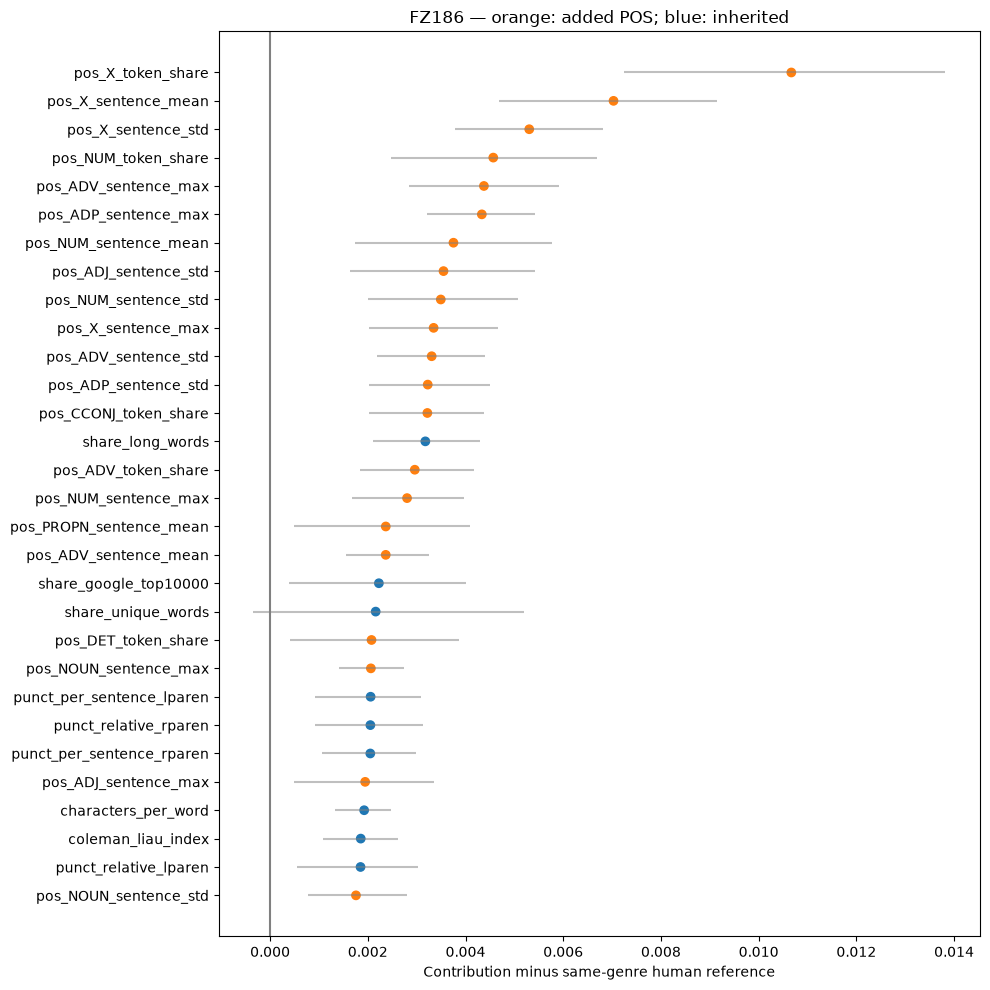

,feature,raw_mean_contribution,human_adjusted_gap,ci_low,ci_high,fraction_AI_directed,block
178,pos_X_token_share,0.006129,0.009814,0.006807,0.012576,0.351852,Added POS
179,pos_X_sentence_mean,0.004095,0.006732,0.004260,0.009071,0.351852,Added POS
180,pos_X_sentence_std,0.003915,0.006071,0.004620,0.007565,0.240741,Added POS
125,pos_ADV_sentence_max,0.003436,0.004613,0.003035,0.006250,0.740741,Added POS
147,pos_NUM_sentence_mean,0.000848,0.004329,0.002412,0.006281,0.722222,Added POS
121,pos_ADP_sentence_max,0.001860,0.003859,0.002685,0.005021,0.814815,Added POS
146,pos_NUM_token_share,0.000539,0.003815,0.001873,0.005832,0.740741,Added POS
124,pos_ADV_sentence_std,0.002567,0.003742,0.002330,0.005046,0.703704,Added POS
120,pos_ADP_sentence_std,0.001917,0.003626,0.002457,0.004805,0.796296,Added POS
181,pos_X_sentence_max,0.001753,0.003477,0.002204,0.004768,0.222222,Added POS


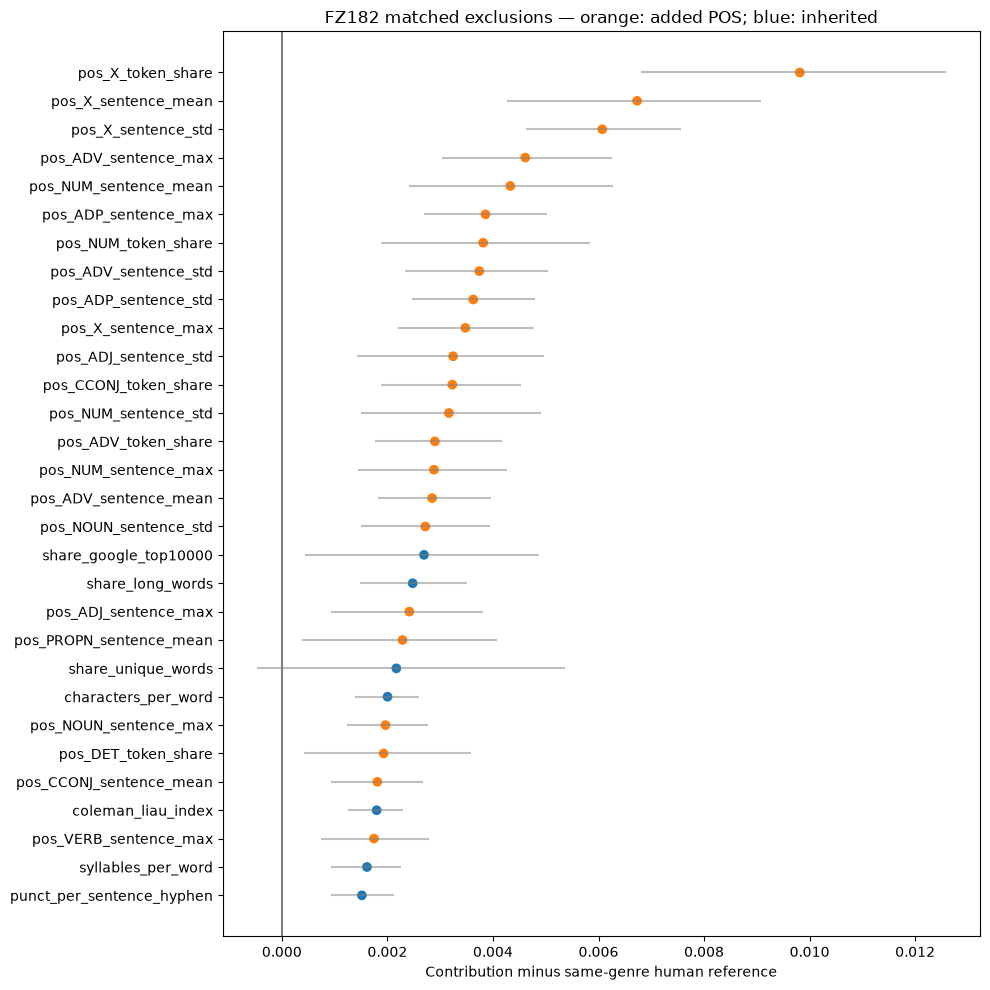

,case_id,source_id,domain,batch,Frozen FZ114,FZ186,FZ182 matched exclusions
0,gate_0001,ai__raid:af383c6d-11c9-4169-a2fa-58280f83ca96,abstracts,Original 27,0.472582,0.681565,0.653126
1,gate_0003,ai__raid:2abdd1df-30c9-4db4-bc75-08ae57b9ec93,news,Original 27,0.675478,0.712704,0.719437
2,gate_0004,ai__raid:f5f280b6-e8c1-4f10-9d16-0e6297e8c730,recipes,New 27,0.342148,0.591278,0.607907
3,gate_0005,ai__raid:7bd2da2a-4f21-4b84-91a7-2cb37fd80071,reddit,New 27,0.441613,0.561215,0.530004
4,gate_0007,ai__raid:ae32af9e-d8dc-415d-bb9f-051981e11dd4,wiki,New 27,0.736448,0.723384,0.710983
5,gate_0015,ai__raid:cfb5728e-c896-4ed5-8173-f39be5ff5f97,abstracts,New 27,0.470296,0.389218,0.410323
6,gate_0016,ai__raid:296752cd-3b82-479f-b5a9-0bb1001ba706,books,New 27,0.625041,0.689994,0.631077
7,gate_0017,ai__raid:b4b807b1-fbfa-43d8-9fc3-61bd36b078ef,news,Original 27,0.549920,0.642377,0.630782
8,gate_0018,ai__raid:6caeff0b-6fa7-4fea-9a48-342fe2d6b83b,recipes,Original 27,0.420377,0.451546,0.487409
9,gate_0019,ai__raid:dc315335-0314-49c5-96b1-3211dc072983,reddit,New 27,0.531791,0.650978,0.648454


,model,AUC,mean_AI_score
0,Frozen FZ114,0.586988,0.477218
1,FZ186,0.800940,0.540866
2,FZ182 matched exclusions,0.790408,0.531238


,model,requested_FPR,threshold,calibration_FPR,test_FPR,TPR,n_AI,n_human
0,Frozen FZ114,0.01,0.601800,0.008418,0.055846,0.129630,54,128
1,Frozen FZ114,0.05,0.570587,0.049757,0.067705,0.166667,54,128
2,Frozen FZ114,0.10,0.555449,0.091403,0.082108,0.185185,54,128
3,Frozen FZ114,0.20,0.511489,0.191530,0.218959,0.370370,54,128
4,Frozen FZ114,0.30,0.489190,0.299223,0.309538,0.425926,54,128
5,Frozen FZ114,0.50,0.438681,0.498366,0.505031,0.629630,54,128
6,Frozen FZ114,1.00,-inf,1.000000,1.000000,1.000000,54,128
7,FZ186,0.01,0.653783,0.008418,0.015988,0.222222,54,128
8,FZ186,0.05,0.602644,0.049798,0.038906,0.370370,54,128
9,FZ186,0.10,0.589020,0.099596,0.050044,0.388889,54,128


,Frozen FZ114,FZ186,FZ182 matched exclusions
batch,,,
New 27,0.486695,0.540170,0.526027
Original 27,0.467741,0.541563,0.536448


CSV and checkpoints: ../results/causal/C03_fz186_raid_fixed54/cfa99a0382fb ; paper figures: ../figures


In [5]:
mix=data.domain.value_counts(normalize=True)
def human_mask(split):return (raid.split.eq(split)&raid.label.eq(0)&raid.domain.isin(mix.index)).to_numpy()
calmask=human_mask('validation');hmask=human_mask('test')
for mask in [calmask,hmask]:
    assert set(mix.index)<=set(raid.loc[mask,'domain']),'Missing human genre'
    assert {text_hash(text_map[s]) for s in raid.loc[mask,'source_id']}.isdisjoint(train_hash|set(data.text.map(text_hash)))
assert {text_hash(text_map[s]) for s in raid.loc[calmask,'source_id']}.isdisjoint({text_hash(text_map[s]) for s in raid.loc[hmask,'source_id']})
def weights(mask):
    g=raid.loc[mask,'domain'];counts=g.value_counts();return np.array([mix[x]/counts[x] for x in g])
wc=weights(calmask);wh=weights(hmask)
for name,mask in [('calibration',calmask),('test',hmask)]:raid.loc[mask,['source_id','domain']].assign(weight=weights(mask)).to_csv(OUT/f'human_{name}_manifest.csv',index=False)
def savefig(fig,stem):
    fig.tight_layout()
    for ext in ['pdf','png']:
        fig.savefig(OUT/f'{stem}.{ext}',dpi=300,bbox_inches='tight')
        fig.savefig(FIG/f'C03_{stem}.{ext}',dpi=300,bbox_inches='tight')
    plt.show()
score_table=data[['case_id','source_id','domain','batch']].copy()
summary=[];ops=[];rocrows=[];ranks=[]
fig,axs=plt.subplots(1,2,figsize=(11,4))
for name,(model,cols) in models.items():
    a=model.predict_proba(XF[cols])[:,1];h=model.predict_proba(XR.loc[hmask,cols])[:,1];cal=model.predict_proba(XR.loc[calmask,cols])[:,1]
    score_table[name]=a
    f,t,ths=roc_curve(np.r_[np.zeros(len(h)),np.ones(54)],np.r_[h,a],sample_weight=np.r_[wh,np.ones(54)/54],drop_intermediate=False)
    summary.append(dict(model=name,AUC=auc(f,t),mean_AI_score=a.mean()))
    for ax in axs:ax.step(f,t,where='post',label=f'{name} ({auc(f,t):.3f})')
    rocrows.extend(dict(model=name,FPR=x,TPR=y) for x,y in zip(f,t))
    cuts=np.r_[np.inf,np.unique(cal)[::-1],-np.inf];cf=np.array([wc[cal>v].sum() for v in cuts])
    for budget in [.01,.05,.10,.20,.30,.50,1.]:
        j=np.flatnonzero(cf<=budget+1e-12)[-1];cut=cuts[j]
        ops.append(dict(model=name,requested_FPR=budget,threshold=cut,calibration_FPR=cf[j],test_FPR=wh[h>cut].sum(),TPR=(a>cut).mean(),n_AI=54,n_human=len(h)))
    # Existing decomposition checks exact reconstruction against this model.
    detector=model
    c=contributions(XF[cols]);hc=contributions(XR.loc[hmask,cols])
    ref=pd.DataFrame(hc,columns=cols).groupby(raid.loc[hmask,'domain'].to_numpy()).mean()
    gap=c-ref.loc[data.domain].to_numpy()
    rng=np.random.default_rng(SEED);boot=np.zeros((B,len(cols)))
    for g in sorted(mix.index):
        ix=np.flatnonzero(data.domain.eq(g));draw=rng.choice(ix,size=(B,len(ix)),replace=True)
        boot+=len(ix)/54*gap[draw].mean(1)
    lo,hi=np.quantile(boot,[.025,.975],axis=0)
    rank=pd.DataFrame(dict(feature=cols,raw_mean_contribution=c.mean(0),human_adjusted_gap=gap.mean(0),ci_low=lo,ci_high=hi,fraction_AI_directed=(gap>0).mean(0)))
    rank['block']=np.where(rank.feature.isin(POS_NAMES),'Added POS','Inherited FZ118')
    rank=rank.sort_values('human_adjusted_gap',ascending=False);ranks.append(rank.assign(model=name))
    stem=name.replace(' ','_')
    rank.to_csv(OUT/f'{stem}_contribution_ranking.csv',index=False)
    pd.DataFrame(c,columns=cols).assign(case_id=data.case_id.to_numpy()).to_csv(OUT/f'{stem}_case_contributions.csv',index=False)
    pd.DataFrame(gap,columns=cols).assign(case_id=data.case_id.to_numpy()).to_csv(OUT/f'{stem}_case_contribution_gaps.csv',index=False)
    display(rank.head(30))
    top=rank.head(30).iloc[::-1];fig2,ax=plt.subplots(figsize=(10,10));y=np.arange(len(top))
    ax.hlines(y,top.ci_low,top.ci_high,color='gray',alpha=.5)
    ax.scatter(top.human_adjusted_gap,y,c=np.where(top.block.eq('Added POS'),'tab:orange','tab:blue'))
    ax.set_yticks(y,top.feature);ax.axvline(0,color='gray');ax.set_title(name+' — orange: added POS; blue: inherited')
    ax.set_xlabel('Contribution minus same-genre human reference');savefig(fig2,f'{stem}_contributions')
for ax in axs:ax.plot([0,1],[0,1],'--',color='gray');ax.set(xlabel='Test human FPR',ylabel='AI TPR');ax.legend(fontsize=8)
axs[1].set_xlim(0,.2);savefig(fig,'fixed54_ROC')
score_table.to_csv(OUT/'fixed54_AI_scores.csv',index=False)
pd.DataFrame(summary).to_csv(OUT/'summary.csv',index=False)
pd.DataFrame(ops).to_csv(OUT/'TPR_at_FPR.csv',index=False)
pd.DataFrame(rocrows).to_csv(OUT/'ROC_points.csv',index=False)
pd.concat(ranks).to_csv(OUT/'all_contribution_rankings.csv',index=False)
display(score_table);display(pd.DataFrame(summary));display(pd.DataFrame(ops))
display(score_table.groupby('batch')[list(models)].mean())
print('CSV and checkpoints:',OUT,'; paper figures:',FIG)
